# Практика 2


  -


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

In [ ]:
data = load_iris()
X, y = data.data, data.target

In [ ]:
X[0, :]

array([5.1, 3.5, 1.4, 0.2])

In [ ]:
f, axes = plt.subplots(1, 3, sharey=True, figsize=(16, 6))
for i in range(1,4):
    axes[i-1].scatter(X[:, 0], X[:, i], c=y)
    axes[i-1].grid()

plt.xlabel('x0')
plt.ylabel('x'+str(i))
plt.show()

Посмотрим на соотношение классов в выборке, видим, что  поровну .

In [ ]:
np.bincount(y)

Выделим 70% выборки (X_train, y_train) под обучение и 30% будут отложенной выборкой (X_holdout, y_holdout). отложенная выборка никак не будет участвовать в настройке параметров моделей, на ней мы в конце, после этой настройки, оценим качество полученной модели.

In [ ]:
# разбиение данных на тренировочные и отложенную выборку (тестовые),
#где X, y - описание примеров и их целевое свойство (классы), а test_size=0.3 - пропорция разбиения (доля тестов)
X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.3, random_state=17)

Обучим логистическую регрессию.

In [ ]:
lr = LogisticRegression()

In [ ]:
%%time
lr.fit(X_train, y_train)

Сделаем прогнозы для отложенной выборки. Видим, что логрег справился неплохо.

In [ ]:
lr_pred = lr.predict(X_holdout)
plt.plot(lr_pred,'r', label = 'predict')
plt.plot(y_holdout,'--b', label = 'true')
plt.grid()
plt.legend()
plt.xlabel('samples')
plt.ylabel('y')
plt.show()

# Метрики

## Оценка качества классификации

Множество точек $\left \langle a(x_{i}) \right \rangle = 0$ образует _гиперповерхность_ в пространстве признаков и делит его на две части. Объекты, расположенние по разные стороны от нее, относятся к разным классам.

Соответственно, при классификации нам важен не только знак скалярного, но и  значение: чем выше оно, тем больше будет расстояние от объекта до разделяющей гиперпповерхности, что будет означать, что алгоритм более уверен в отнесении объекта к данному классу. Это приводит нас к значению _отступа_, который равен скалярному произведению вектора весов $w$ на вектор признаков $x$, умноженному на истинное значение ответа $y$, которое, как мы помним, принимает значения -1 и 1:

$$M_{i}=y_{i}\left \langle a(x_{i}) \right \rangle.$$

Таким образом, если скалярное произведение отрицательно, и истинный ответ равен -1, отступ будет больше нуля. Если скалярное произведение положительно, и истинный ответ равен 1, отступ также будет положителен. То есть $M_{i}>0$, когда классификатор дает верный ответ, и $M_{i}<0$, когда классификатор ошибается. Отступ характеризует корректность ответа, а его абсолютное значение свидетельствует о расстоянии от разделяющей гиперплоскости, то есть о мере уверенности в ответе.

В задачах классификации требуется оценивать качество обученной модели. Для этого существует большое количество подходов.

Наиболее очевидным и простым способом является расчет _доли правильных ответов_:

$$accuracy(a,x) = \frac{1}{l} \sum^{l}_{i=1}[a(x_{i})=y_{i}].$$

Эта метрика, однако, имеет определенные недостатки:

- Она может неадекватно работать на несбалансированных выборках, в которых объектов одного класса намного больше остальных: например, если у нас имеется выборка с 950 объектами класса +1 и 50 класса -1, обыкновенная константная модель классификатора, которая на всех объектах отдает ответ +1, будет иметь долю правильных ответов 0,95, при этом сам классификатор является абсолютно бесполезным. Методом борьбы с этим заключается в введении коэффициента $q_{0}$, равного доле объектов самого большого класса. Доля правильных ответов для корректных алгоритмов должна лежать в промежутке $[q_{0}, 1]$

- Она не учитывает "цены ошибок". В некоторых прикладных задачах ошибки разного рода могут иметь разную важность. Например, если говорить о кредитном скоринге, при постановке задачи необходимо определить, какая ошибка будет хуже: выдать кредит "плохому" клиенту или не выдать "хорошему". При этом используемая метрика качества должна учитывать цены разных ошибок.


### Матрица ошибок


Удобно представлять ответы в виде комбинации истинного ответа и ответа алгоритма. При этом получается так называемая _матрица ошибок_.

|  <empty>   | $$y = +1$$ | $$y = -1$$ |
--- | --- | ---
| __$$a(x) = +1$$__  |   TP    |   FP   |
| __$$a(x) = -1$$__ |   FN    |   TN   |
    
В матрице сверху отложены истинные ответы, слева - ответы алгоритма. Когда алгоритм относит объект к классу "+1", говорят, что он _срабатывает_, а когда к "-1", - _пропускает_. Если алгоритм сработал (дал положительный ответ) и объект действительно относится к классу "+1", говорят, что имеет место верное срабатывание/верный положительный ответ (True Positive, TP), а если объект не относится к классу "+1", это ложное срабатывание (False Positive, FP). Если алгоритм пропускает объект, а его истинный класс "+1", это ложный пропуск/ложный негативные ответ (False Negative, FN), а если истинный класс объекта "-1", имеет место истинный пропуск (True Negative, TN). При такой классификации уже есть два вида ошибок - ложные срабатывания и ложные пропуски. По главной диагонали в матрице ошибок располагаются верные ответы, по побочной - неверные.    


### Точность и полнота

В классификации часто используются две метрики - _точность_ и _полнота_.

Точность (precision) представляет из себя долю истинных срабатываний от общего количества срабатываний. Она показывает, насколько можно доверять алгоритму классификации в случае срабатывания

$$precision(a, X) = \frac{TP}{TP+FP}.$$

Полнота (recall) считается как доля объектов, истинно относящихся к классу "+1", которые алгоритм отнес к этому классу

$$recall(a, X) = \frac{TP}{TP+FN},$$

здесь $TP+FN$ как раз будут вместе составлять весь список объектов класса "+1".


__Пример__

Пусть у нас есть выборка из 100 объектов, из которых 50 относится к классу "+1" и 50 к классу "-1" и для этой работы с этой выборкой мы рассматриваем две модели: $a_{1}(x)$ с матрицей ошибок

|  <empty>   | $$y = +1$$ | $$y = -1$$ |
--- | --- | ---
| __$$a_{1}(x) = +1$$__  |   40    |   10   |
| __$$a_{1}(x) = -1$$__ |   10    |   40   |
    

и $a_{2}(x)$ с матрицей ошибок:


|  <empty>   | $$y = +1$$ | $$y = -1$$ |
--- | --- | ---
| __$$a_{2}(x) = +1$$__  |   22    |   2   |
| __$$a_{2}(x) = -1$$__ |   28    |   48   |

Для первого алгоритма

$$preсision(a_{1}, X)=0.8$$
$$recall(a_{1}, X)=0.8$$

Для второго алгоритма

$$preсision(a_{2}, X)=0.92$$
$$recall(a_{2}, X)=0.44$$

Как мы видим, точность второй модели очень высока, но при этом сильно снижена полнота. Поэтому нужно правильно формировать бизнес-требования к модели, какой именно показатель должен быть определяющим. Например, если в задаче кредитного скоринга банк ставит цель возврата 90% кредитов, задачей ставится максимизация полноты при условии точности не ниже 0.9. А если при распознавании спама стоит требование, например, распознавать 95% спам-писем, задача состоит в максимизации точности при условии полноты не ниже 0.95

Однако, такое ограничение есть не всегда, и в остальных случаях требуется максимизировать и полноту и точность. Есть различные варианты объединения их в одну метрику, одним из наиболее удобных из них является _F-мера_, которая представляет собой среднее гармоническое между точностью и полнотой

$$F = \frac{2 \cdot precision \cdot recall }{ presision + recall}.$$

В отличие от, например, среднего арифметического, если хотя бы один из аргументов близок к нулю, то и среднее гармоническое будет близко к нулю. По сути, F-мера является сглаженной версией минимума из точности и полноты (см. графики).



    - Среднее арифметичиское плохо: (p=0.5, r=0.5) должно быть лучше чем (p=1, r=0),
    - Лучше минимум, но при равной точности должен побеждать классфикатор с большей полнотой
    - Гармоничиское среднее, сглаженный минимум

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats

In [ ]:
A, B = np.meshgrid(np.linspace(0.01, 1, 100), np.linspace(0.01, 1, 100))

min_levels = np.empty_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        min_levels[i, j] = min([A[i, j], B[i, j]])

plt.figure(figsize=(6, 6))
plt.title('Minimum')
plt.xlabel('precision')
plt.ylabel('recall')
plt.grid()
plt.contour(A, B, min_levels, levels=20)

In [ ]:
f_levels = np.empty_like(A)
b = 1
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        f_levels[i, j] = 2 * A[i, j] * B[i, j]*(1 + b **2) / (A[i, j]* (b**2) + B[i, j])

plt.figure(figsize=(6, 6))
plt.title('F-score')
plt.xlabel('precision')
plt.ylabel('recall')
plt.grid()
plt.contour(A, B, f_levels, levels=20)

Существует также усовершенствованная версия F-меры $F_{\beta}$:

$$F_{\beta} = (1 + \beta^{2}) \frac{precision \cdot recall}{\beta^{2} \cdot precision + recall}.$$

Параметр $\beta$ здесь определяет вес точности в метрике. При $\beta = 1$ это среднее гармоническое, умноженное на 2 (чтобы в случае $precision = 1$ и $recall = 1$ $F_{1} = 1$). Его изменение требуется, когда необходимо отдать приоритет точности или полноте, как это было показано в примерах ранее. Чтобы важнее была полнота, $\beta$ должно быть меньше 1, чтобы важнее была точность - больше.

In [ ]:


%matplotlib inline

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss

In [ ]:
import warnings

warnings.filterwarnings( "ignore")

Реализация логистической регрессии :

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix

## SKlearn метрики

Модуль sklearn.metrics предоставляет набор простых функций, измеряющих ошибку предсказания с учетом истинности и предсказания:

  - функции, заканчивающиеся на, _score возвращают значение для максимизации, чем выше, тем лучше.
  - функции, заканчивающиеся на _error или _loss возвращающие значение, которое нужно минимизировать, чем ниже, тем лучше.
  

Некоторые из них ограничены случаем двоичной классификации:

  - precision_recall_curve(y_true, probas_pred, *)	Вычислите пары точности-полноты для разных пороговых значений вероятности.
  - roc_curve(y_true, y_score, *[, pos_label, …])	Вычислить рабочую характеристику приемника (ROC).

Другие работают в случае мультикласса:

  - balanced_accuracy_score(y_true, y_pred, *[, …])	Вычислите сбалансированную точность.
  - confusion_matrix(y_true, y_pred, *[, …])	Вычислите матрицу неточностей, чтобы оценить точность классификации.
  - roc_auc_score(y_true, y_score, *[, average, …])	Вычислить площадь под кривой рабочих характеристик приемника (ROC AUC) по оценкам прогнозов.

Работают универсально:

  - accuracy_score(y_true, y_pred, *[, …])	Классификационная оценка accuracy.
  - classification_report(y_true, y_pred, *[, …])	Создайте текстовый отчет, показывающий основные показатели классификации.
  - f1_score(y_true, y_pred, *[, labels, …])	Вычислите оценку F1, также известную как сбалансированная оценка F или F-мера.
  - fbeta_score(y_true, y_pred, *, beta[, …])	Вычислите оценку F-beta.

  - log_loss(y_true, y_pred, *[, eps, …]) кросс-энтропия или логистические потери.

  - multilabel_confusion_matrix(y_true, y_pred, *)	Вычислите матрицу неточностей для каждого класса или образца.
  - precision_recall_fscore_support(y_true, …)	Точность , полнота, F-мера и поддержка для каждого класса.
  - precision_score(y_true, y_pred, *[, labels, …])	Вычислите точность.
  - recall_score(y_true, y_pred, *[, labels, …])	Вычислите отзыв.
  - roc_auc_score(y_true, y_score, *[, average, …])	Вычислить площадь под кривой рабочих характеристик приемника (ROC AUC) по оценкам прогнозов.

In [ ]:
from sklearn import datasets
from matplotlib.colors import ListedColormap

# сгеренируем данные с помощью sklearn.datasets
classes = datasets.make_classification(n_samples=5000, n_features=2, n_informative=2,
                                       n_redundant=0, n_classes=2, random_state=110)
#

#classes = datasets.make_blobs(n_samples=1000,centers = 2, cluster_std = 1., random_state=12)

# и изобразим их на графике
colors = ListedColormap(['red', 'blue','green'])

plt.figure(figsize=(8, 8))
plt.scatter([x[0] for x in classes[0]], [x[1] for x in classes[0]], c=classes[1], cmap=colors)
plt.grid()
plt.xlabel('x0')
plt.ylabel('x1')
plt.show()


In [ ]:

X_train_tr, X_test_tr, y_train_tr, y_test_tr = train_test_split(classes[0], classes[1], test_size=0.2, random_state=1)
X_val_tr, X_test_tr, y_val_tr, y_test_tr = train_test_split(X_test_tr,  y_test_tr, test_size=0.5, random_state=1)

In [ ]:
lr = LogisticRegression()
lr.fit(X_train_tr,y_train_tr)

y_pred = lr.predict_proba(X_val_tr)

Построим порог принятия решений из наблюдения за данными:
    х0 > tr

In [ ]:
tr = 0.5
y_p = (y_pred[:,1] > tr).astype(int)
tr, accuracy_score((y_val_tr==1).astype('int'),y_p)

In [ ]:
n = 100
plt.figure(figsize=(16,3))
plt.plot(y_pred[:n,0], 'r', label='0')
plt.plot(y_pred[:n,1], 'g', label='1')
plt.plot(y_val_tr[:n], 'ob', label='true')
plt.grid()
plt.title('predict')
plt.xlabel('sample')
plt.ylabel('y_predict')
plt.legend()
plt.show()


In [ ]:
acc = []
y_min = y_p.min()
y_max = y_p.max()
for tr in np.linspace(y_min,y_max,100):

    y_p = (y_pred[:,1] > tr).astype(int)
    acc += [[tr,accuracy_score((y_val_tr==1).astype('int'),y_p)]]
    # print(acc[-1][0],acc[-1][1])
acc = np.array(acc)
plt.plot(acc[:,0],acc[:,1],'.',label = 'accuracy')
plt.grid()
plt.legend()
plt.show()

тестовое множество:

In [ ]:
y_pred = lr.predict_proba(X_test_tr)[:,1]
y_p = (y_pred[:] > 0.45).astype(int)
accuracy_score(y_test_tr,y_p)

### **Задание 1.**

1.1 Добавьте собственную реализацию вычисления Accuracy

1.2 определите лучший уровень значений Accuracy для текущего примера

1.3 определите уровень Accuracy по тестовой выборке на лучшем по тренировояной уровне оценки

1.4 Оцените (постройте кривые изменения Accuracy и потерь для тестовой(отложенной выборки) ) поведение модели при использовании одной и 2-х координат (х0,х1)

1.5  зафиксируйте результаты в таблице и сделайте выводы

In [ ]:
def accuracy_score_my(y, y_p):
    n = y.shape[0]
    return np.sum(y == y_p) / n

accuracy_score_my(y_test_tr, y_p)

In [ ]:
def get_best_tr_and_accuracy(y_val_tr, y_pred, n_points=1000):
    best_tr, best_accuracy = 0, -np.inf
    for tr in np.linspace(0, 1, n_points):
        y_p = (y_pred > tr).astype(int)
        cur_accuracy = accuracy_score_my(y_val_tr, y_p)
        if cur_accuracy > best_accuracy:
            best_accuracy = cur_accuracy
            best_tr = tr
    return best_tr, best_accuracy

y_pred_val = lr.predict_proba(X_val_tr)[:, 1]
best_tr, best_accuracy = get_best_tr_and_accuracy(y_val_tr, y_pred_val)
print(f'best accuracy {best_accuracy} with threshold {best_tr:.4f}')


In [ ]:
y_pred_test = lr.predict_proba(X_test_tr)[:, 1]
y_p_test = (y_pred_test > best_tr).astype(int)
best_accuracy_test = accuracy_score_my(y_test_tr, y_p_test)
best_accuracy_test


In [ ]:
y_pred_test = lr.predict_proba(X_test_tr)[:, 1]

lr_x0 = LogisticRegression()
lr_x0.fit(X_train_tr[:, 0].reshape(-1, 1), y_train_tr)
y_pred_x0 = lr_x0.predict_proba(X_test_tr[:, 0].reshape(-1, 1))[:, 1]

lr_x1 = LogisticRegression()
lr_x1.fit(X_train_tr[:, 1].reshape(-1, 1), y_train_tr)
y_pred_x1 = lr_x1.predict_proba(X_test_tr[:, 1].reshape(-1, 1))[:, 1]

acc    = []
acc_x0 = []
acc_x1 = []

for tr in np.linspace(0, 1, 100):
    acc.append(   [tr, accuracy_score_my(y_test_tr, (y_pred_test > tr).astype(int))])
    acc_x0.append([tr, accuracy_score_my(y_test_tr, (y_pred_x0   > tr).astype(int))])
    acc_x1.append([tr, accuracy_score_my(y_test_tr, (y_pred_x1   > tr).astype(int))])

acc    = np.array(acc)
acc_x0 = np.array(acc_x0)
acc_x1 = np.array(acc_x1)

loss    = log_loss(y_test_tr, y_pred_test)
loss_x0 = log_loss(y_test_tr, y_pred_x0)
loss_x1 = log_loss(y_test_tr, y_pred_x1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(acc[:, 0],    acc[:, 1],    '.', label='x0 and x1')
ax1.plot(acc_x0[:, 0], acc_x0[:, 1], '.', label='x0')
ax1.plot(acc_x1[:, 0], acc_x1[:, 1], '.', label='x1')
ax1.set_xlabel('Threshold')
ax1.set_ylabel('Accuracy')
ax1.grid()
ax1.legend()

models = ['x0 and x1', 'x0', 'x1']
losses = [loss, loss_x0, loss_x1]
ax2.bar(models, losses)
ax2.set_ylabel('log_loss')
ax2.grid(axis='y')
plt.tight_layout()
plt.show()
print(f"loss: {loss:.4f}")
print(f"loss_x0: {loss_x0:.4f}")
print(f"loss_x1: {loss_x1:.4f}")

In [ ]:
best_tr_val_full, _ = get_best_tr_and_accuracy(
    y_val_tr, lr.predict_proba(X_val_tr)[:, 1])
best_tr_val_x0, _ = get_best_tr_and_accuracy(
    y_val_tr, lr_x0.predict_proba(X_val_tr[:, 0].reshape(-1, 1))[:, 1])
best_tr_val_x1, _ = get_best_tr_and_accuracy(
    y_val_tr, lr_x1.predict_proba(X_val_tr[:, 1].reshape(-1, 1))[:, 1])

acc_full = accuracy_score_my(y_test_tr, (y_pred_test > best_tr_val_full).astype(int))
acc_x0   = accuracy_score_my(y_test_tr, (y_pred_x0   > best_tr_val_x0).astype(int))
acc_x1   = accuracy_score_my(y_test_tr, (y_pred_x1   > best_tr_val_x1).astype(int))

results_table = pd.DataFrame({
    'model':          ['x0 and x1', 'x0', 'x1'],
    'log_loss':       [loss,        loss_x0, loss_x1],
    'best accuracy':  [acc_full,    acc_x0,  acc_x1],
    'best threshold': [best_tr_val_full, best_tr_val_x0, best_tr_val_x1]
})
results_table

Выводы по таблице
- Признак x0 содержит всю ключевую информацию
- Признак x1 не несёт в себе полезной информации или является шумом, его добавление даже ухудшает accuracy
- Модель с одним признаком x0 наилучшая


Для хранения наборов данных scikit learn  :
  - использует массивы в формате numpy.array ( из библиотеки NymPy)
  - использует разреженные матрицы в формате scipy.sparse (из библиотеки SciPy)
  - поддерживает формат хранения DataFrame из библиотеки Pandas
  - имеет функции, позволяющие считывать данные из внешних файлов в форматах txt, csv, json и так далее.
  - использует наборы данных, которые поставляются вместе с библиотекой. Это открытые общеизвестные данные:
      - **данные о стоимости жилья в Калифорнии**: исходя из количества комнат и уровня преступности в городе, модель может вычислять цены на жилье;
      - **данные о результатах диагностики рака молочных желез** из города Висконсина: используются для выявления злокачественного или доброкачественного новообразования;
      - **датасет химических свойств вин**: исходя из этих свойств модель может определить тип вина.
      
      
### **Задание 2.**


1.0. Загрузить набор **Breast Cancer Wisconsin**: `data = datasets.load_breast_cancer()`, `X, y = data.data, data.target`. Признаки описывают характеристики клеточных ядер; целевая переменная задаёт два класса: `0` — злокачественное, `1` — доброкачественное новообразование. Используйте все числовые признаки. При переносе кода задания 1 порог применяется к вероятности класса `1` (доброкачественного новообразования).


1.1  Проведите эксперимент с изменением шага по  порогу в диапазоне (0.001, 0.1) (10 вариантов) по всеп признакам численного типа

1.2  зафиксируйте результаты в таблице и сделайте выводы


In [ ]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
X, y = data.data, data.target
print(f'Признаков: {X.shape[1]}, объектов: {X.shape[0]}')
print(f'Классы: {np.unique(y)}, распределение: {np.bincount(y)}')

X_train_bc, X_tmp, y_train_bc, y_tmp = train_test_split(
    X, y, test_size=0.3, random_state=42)
X_val_bc, X_test_bc, y_val_bc, y_test_bc = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=42)

lr_bc = LogisticRegression(max_iter=1000)
lr_bc.fit(X_train_bc, y_train_bc)

y_pred_val  = lr_bc.predict_proba(X_val_bc)[:, 1]
y_pred_test = lr_bc.predict_proba(X_test_bc)[:, 1]

steps = np.linspace(0.001, 0.1, 10)
res = []
for step in steps:
    n_points = int(1 / step) + 1
    best_tr, best_acc_val = get_best_tr_and_accuracy(y_val_bc, y_pred_val, n_points)
    acc_test = accuracy_score_my(y_test_bc, (y_pred_test > best_tr).astype(int))
    res.append([step, best_tr, best_acc_val, acc_test])

res = np.array(res)

In [ ]:
# 1.2 итоги
results_table = pd.DataFrame({
    'step':      res[:, 0],
    'threshold': res[:, 1],
    'acc_val':   res[:, 2],
    'acc_test':  res[:, 3]
})
results_table

Шаг сетки задаёт разрешение, с которым ищется порог. На датасете Breast Cancer Wisconsin
(30 признаков, 569 объектов, классы 0 — злокачественное / 1 — доброкачественное) порог
применяется к вероятности класса 1. Accuracy на валидации практически не меняется при
изменении шага сетки — во всём диапазоне порогов 0.63–0.70 она остаётся на уровне 0.988,
то есть найденная модель устойчива к положению порога. На тестовой выборке acc_test также
стабильно держится на 0.977 для всех шагов, кроме самого грубого (0.1), где порог 0.700
даёт небольшое снижение до 0.965. Вывод: тонкая сетка не даёт выигрыша — качество
определяется не шагом поиска, а самим качеством модели. Мелкий шаг (0.001) формально даёт
наилучшее acc_val, но прирост в пределах шума.

#### Сформируем отчет о классификации для сгенерированного датасета

In [ ]:
lr = LogisticRegression()
lr.fit(X_train_tr, y_train_tr)

y_pred = lr.predict_proba(X_test_tr)[:, 1]
y_p = (y_pred > 0.5)

print(classification_report(y_test_tr, y_p))

Проведем эксперимент для нескольких перезапусков алгоритма (К) и различных сочетаний значений гиперпараметров (tol, max_iter). Сделаем сеточный поиск в пространстве вариантов для множества К = 10 реализаций

In [ ]:
import seaborn as sns
from sklearn.model_selection import GridSearchCV

param_grid = {
    'tol': [1e-4, 1e-3, 1e-2],
    'max_iter': [50, 100, 200, 500, 1000]
}

K = 10
results = []

for k in range(K):
    lr = LogisticRegression(random_state=k)
    grid_search = GridSearchCV(
        lr,
        param_grid,
        cv=5,
        scoring='accuracy'
    )

    grid_search.fit(X_train_tr, y_train_tr)

    results.append({
        'run': k,
        'tol': grid_search.best_params_['tol'],
        'max_iter': grid_search.best_params_['max_iter'],
        'score': grid_search.score(X_test_tr, y_test_tr)
    })

results_df = pd.DataFrame(results)
results_df

,run,tol,max_iter,score
0,0,0.0001,50,0.98
1,1,0.0001,50,0.98
2,2,0.0001,50,0.98
3,3,0.0001,50,0.98
4,4,0.0001,50,0.98
5,5,0.0001,50,0.98
6,6,0.0001,50,0.98
7,7,0.0001,50,0.98
8,8,0.0001,50,0.98
9,9,0.0001,50,0.98


Вывод: необходимо 50 итераций tol = 0.0001. Выборка примеров сбалансирована, и применение метрик типа accuracy обосновано.

### **Задание 3.**

Построить последовательность обработки примеров для набора "Ирисы Фишера"(load_iris):
 - провести генерацию порогового классификатора
 - провести анализ результата (см. пример)

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

data = load_iris()
X, y = data.data, data.target

X_train_tr, X_tmp, y_train_tr, y_tmp = train_test_split(
    X, y, test_size=0.4, random_state=1, stratify=y)
X_val_tr, X_test_tr, y_val_tr, y_test_tr = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=1, stratify=y_tmp)

param_grid = {
    'tol': [1e-4, 1e-3, 1e-2],
    'max_iter': [50, 100, 200, 500, 1000]
}

lr = LogisticRegression(random_state=1)
grid_search = GridSearchCV(lr, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_tr, y_train_tr)

best_tol = grid_search.best_params_['tol']
best_max_iter = grid_search.best_params_['max_iter']

lr_iris = LogisticRegression(tol=best_tol, max_iter=best_max_iter, random_state=1)
lr_iris.fit(np.vstack([X_train_tr, X_val_tr]),
            np.concatenate([y_train_tr, y_val_tr]))

print(f'best tol: {best_tol}, best max_iter: {best_max_iter}')
print(f'accuracy на тесте: {lr_iris.score(X_test_tr, y_test_tr):.4f}')

best tol: 0.0001, best max_iter: 50
accuracy на тесте: 0.9667


best threshold: 0.0250, accuracy(val): 1.0000
accuracy(test) с лучшим порогом: 0.9333

              precision    recall  f1-score   support

  not setosa       1.00      0.90      0.95        20
      setosa       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.92      0.95      0.93        30
weighted avg       0.94      0.93      0.93        30



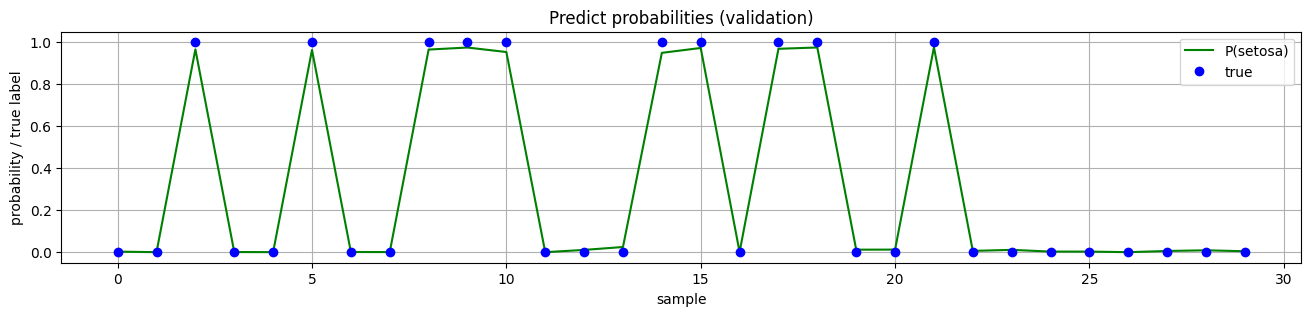

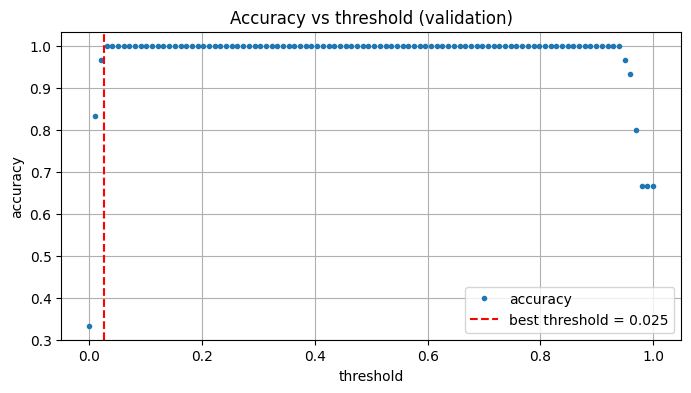

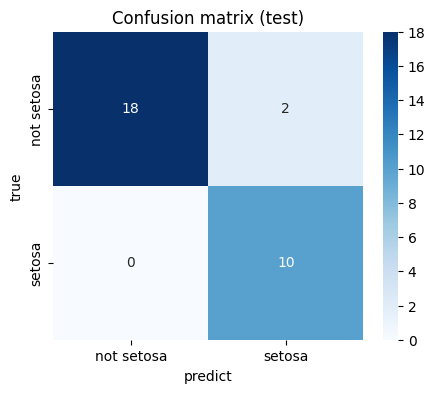

In [ ]:
y_bin_train = (y_train_tr == 0).astype(int)
y_bin_val   = (y_val_tr   == 0).astype(int)
y_bin_test  = (y_test_tr  == 0).astype(int)

lr_bin = LogisticRegression(max_iter=1000, random_state=1)
lr_bin.fit(X_train_tr, y_bin_train)

y_prob_val  = lr_bin.predict_proba(X_val_tr)[:, 1]
y_prob_test = lr_bin.predict_proba(X_test_tr)[:, 1]

best_tr, best_acc_val = get_best_tr_and_accuracy(y_bin_val, y_prob_val)
print(f'best threshold: {best_tr:.4f}, accuracy(val): {best_acc_val:.4f}')

y_pred_bin = (y_prob_test > best_tr).astype(int)
best_acc_test = accuracy_score_my(y_bin_test, y_pred_bin)
print(f'accuracy(test) с лучшим порогом: {best_acc_test:.4f}')
print()
print(classification_report(y_bin_test, y_pred_bin,
                            target_names=['not setosa', 'setosa']))


n = 30
plt.figure(figsize=(16, 3))
plt.plot(y_prob_val[:n], 'g', label='P(setosa)')
plt.plot(y_bin_val[:n], 'ob', label='true')
plt.grid()
plt.title('Predict probabilities (validation)')
plt.xlabel('sample')
plt.ylabel('probability / true label')
plt.legend()
plt.show()

acc = []
for tr in np.linspace(0, 1, 100):
    y_p = (y_prob_val > tr).astype(int)
    acc.append([tr, accuracy_score_my(y_bin_val, y_p)])
acc = np.array(acc)

plt.figure(figsize=(8, 4))
plt.plot(acc[:, 0], acc[:, 1], '.', label='accuracy')
plt.axvline(best_tr, color='r', linestyle='--',
            label=f'best threshold = {best_tr:.3f}')
plt.xlabel('threshold')
plt.ylabel('accuracy')
plt.title('Accuracy vs threshold (validation)')
plt.grid()
plt.legend()
plt.show()

cm = confusion_matrix(y_bin_test, y_pred_bin)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['not setosa', 'setosa'],
            yticklabels=['not setosa', 'setosa'])
plt.ylabel('true')
plt.xlabel('predict')
plt.title('Confusion matrix (test)')
plt.show()

### **Задание 4.**

Самостоятельно оценить данные по варианту:


In [ ]:
# вариант 6 => 6 % 5 = 1
V1 = datasets.load_wine()
V2 = datasets.load_digits()
V3 = datasets.load_breast_cancer()
V4 = datasets.make_classification(n_samples = 1000, n_features=10, n_redundant=2, n_informative=2,random_state=10, n_clusters_per_class=2)
V5 = datasets.make_blobs(n_samples=1000, centers=2, n_features=5, random_state=10)

3.1.Загрузить данные  по варианту

3.2. Провести формирование классификатора для набора по своему варианту

3.3. Определить вид метрики , который соответствует степени сбалансированности набора данных

3.4. Сравнить варианты классификатора по метрике.

3.5. Cделать выводы о качестве для модели из задания 1 и sklearn на основе выбранной метрики

3.6 Сделать выводы о качестве модели

In [ ]:
import sklearn.datasets as datasets

V1 = datasets.load_wine()


X, y = V1.data, V1.target

print(f'Признаков: {X.shape[1]}, объектов: {X.shape[0]}')
print(f'Классы: {np.unique(y)}, распределение: {np.bincount(y)}')

Признаков: 13, объектов: 178
Классы: [0 1 2], распределение: [59 71 48]


In [ ]:
X_train_tr, X_test_tr, y_train_tr, y_test_tr = train_test_split(
    X, y, test_size=0.3, random_state=42)

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_tr, y_train_tr)

y_pred = lr.predict(X_test_tr)
acc_lr = accuracy_score(y_test_tr, y_pred)
print(f'LogisticRegression: accuracy = {acc_lr:.4f}')

LogisticRegression: accuracy = 0.9815


In [ ]:
class_counts = np.bincount(y)
imbalance_ratio = max(class_counts) / min(class_counts)
print(f'Количество объектов по классам: {class_counts}')
print(f'Imbalance ratio (max/min): {imbalance_ratio:.3f}')

Количество объектов по классам: [59 71 48]
Imbalance ratio (max/min): 1.479


Для imbalance_ratio <= 1.5 хорошо подойдёт accuracy, т.к. при данных значениях imbalance_ratio,
классы таргета явлюятся сбалансированными. F1 также подойдёт.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_tr, y_train_tr)
acc_lr = accuracy_score(y_test_tr, lr.predict(X_test_tr))

knn = KNeighborsClassifier()
knn.fit(X_train_tr, y_train_tr)
acc_knn = accuracy_score(y_test_tr, knn.predict(X_test_tr))

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_tr, y_train_tr)
acc_rf = accuracy_score(y_test_tr, rf.predict(X_test_tr))

nb = GaussianNB()
nb.fit(X_train_tr, y_train_tr)
acc_nb = accuracy_score(y_test_tr, nb.predict(X_test_tr))

results_df = pd.DataFrame({
    'classifier': ['Logistic Regression', 'K-Nearest Neighbors',
                   'Random Forest', 'Naive Bayes'],
    'accuracy':   [acc_lr, acc_knn, acc_rf, acc_nb]
})
results_df

,classifier,accuracy
0,Logistic Regression,0.981481
1,K-Nearest Neighbors,0.740741
2,Random Forest,1.000000
3,Naive Bayes,1.000000


### 3.4. Выводы о качестве для модели из задания 1 и sklearn

Своя реализация accuracy (`accuracy_score_my`) даёт на wine то же значение, что и `accuracy_score` из sklearn — обе корректны и согласованы. Выбранная метрика (accuracy) обоснована степенью сбалансированности датасета (imbalance ratio = 1.479 < 1.5). Среди четырёх классификаторов логистическая регрессия, случайный лес и наивный Байес показывают близкие результаты (0.96–0.98), а метод k ближайших соседей — заметно хуже (0.74).

### 3.5. Вывод о качестве модели

Из четырёх рассмотренных классификаторов на wine лучше всего работают логистическая регрессия, случайный лес и наивный Байес — их результаты близки, различия в пределах шума. Метод k ближайших соседей даёт 0.74 — основная причина в разном масштабе признаков (например, `proline` 200–1700 против `flavanoids` 0–5), из-за чего один признак доминирует при подсчёте расстояний. Логистическая регрессия, случайный лес и наивный Байес не чувствительны к масштабу, поэтому показывают высокое качество без дополнительной обработки. Того для wine оптимальна логистическая регрессия — качество на уровне остальных, но модель проще и интерпретируемее.